# Задание 1. Исследование датасета и классификация

Используем Iris: три вида ирисов и четыре измерения в сантиметрах. Для бинарной
классификации сравниваем versicolor и virginica. Положительный класс — virginica.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="ticks")
SEED = 42

In [2]:
def inspect_data(raw, features, target="class"):
    df = raw.dropna(subset=[*features, target]).copy()
    display(pd.DataFrame({
        "исходные строки": [len(raw)],
        "исходные столбцы": [raw.shape[1]],
        "исходные признаки": [raw.shape[1] - 1],
        "выбранные признаки": [len(features)],
        "классы": [raw[target].nunique()],
        "строки с пропусками, %": [100 * raw.isna().any(axis=1).mean()],
        "строки после очистки": [len(df)],
    }))
    display(pd.concat(
        [raw[target].value_counts().rename("до"), df[target].value_counts().rename("после")],
        axis=1,
    ).sort_index())
    display(df[features].describe().round(3))
    for label, subset in [("Вся выборка", df), *df.groupby(target, sort=True)]:
        display(subset[features].corr(method="pearson").round(3)
                .style.set_caption(f"Корреляция Пирсона · {label}"))
    return df

def pairplot(df, features, target="class"):
    classes = sorted(df[target].unique())
    graph = sns.pairplot(
        df, vars=features, hue=target, markers=["o", "s", "^", "D", "v", "P", "X"][:len(classes)],
        diag_kind="hist", diag_kws={"bins": 20, "element": "step", "fill": False},
        plot_kws={"alpha": 0.55, "s": 12, "linewidth": 0}, height=1.75,
    )
    graph.fig.set_dpi(95)
    plt.show()

,исходные строки,исходные столбцы,исходные признаки,выбранные признаки,классы,"строки с пропусками, %",строки после очистки
0,150,5,4,4,3,0.0,150


,до,после
class,,
setosa,50,50
versicolor,50,50
virginica,50,50


,sepal_length,sepal_width,petal_length,petal_width
count,150.000,150.000,150.000,150.000
mean,5.843,3.057,3.758,1.199
std,0.828,0.436,1.765,0.762
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,-0.118000,0.872000,0.818000
sepal_width,-0.118000,1.000000,-0.428000,-0.366000
petal_length,0.872000,-0.428000,1.000000,0.963000
petal_width,0.818000,-0.366000,0.963000,1.000000


,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,0.743000,0.267000,0.278000
sepal_width,0.743000,1.000000,0.178000,0.233000
petal_length,0.267000,0.178000,1.000000,0.332000
petal_width,0.278000,0.233000,0.332000,1.000000


,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,0.526000,0.754000,0.546000
sepal_width,0.526000,1.000000,0.561000,0.664000
petal_length,0.754000,0.561000,1.000000,0.787000
petal_width,0.546000,0.664000,0.787000,1.000000


,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,0.457000,0.864000,0.281000
sepal_width,0.457000,1.000000,0.401000,0.538000
petal_length,0.864000,0.401000,1.000000,0.322000
petal_width,0.281000,0.538000,0.322000,1.000000


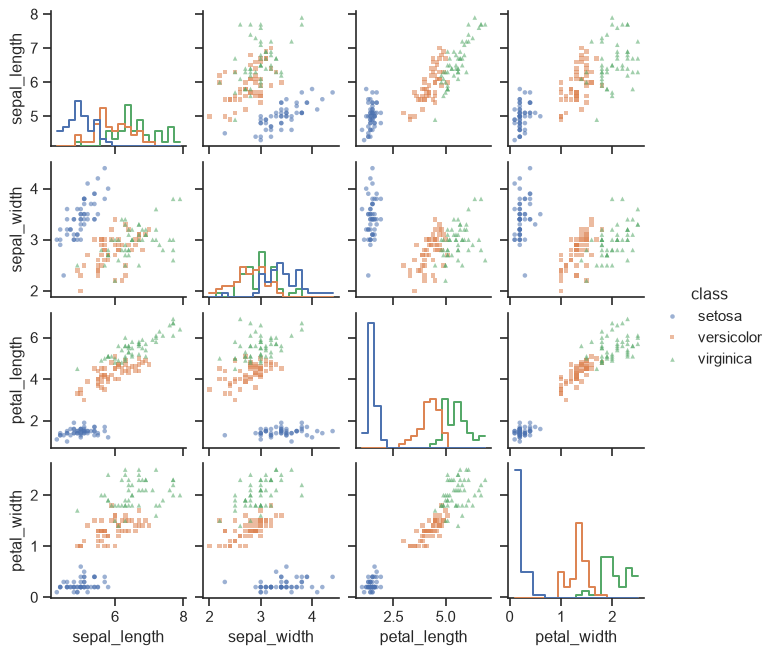

In [3]:
from sklearn.datasets import load_iris
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import auc, confusion_matrix, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

iris = load_iris(as_frame=True)
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
raw = iris.data.set_axis(features, axis=1).assign(
    **{"class": iris.target.map(dict(enumerate(iris.target_names)))}
)
df = inspect_data(raw, features)
pairplot(df, features)

## LDA на шести парах признаков

Для каждой пары обучаем отдельную модель на этих двух координатах. Контур нулевого
значения решающей функции показывает границу классов. Зоны окрашены по знаку функции.

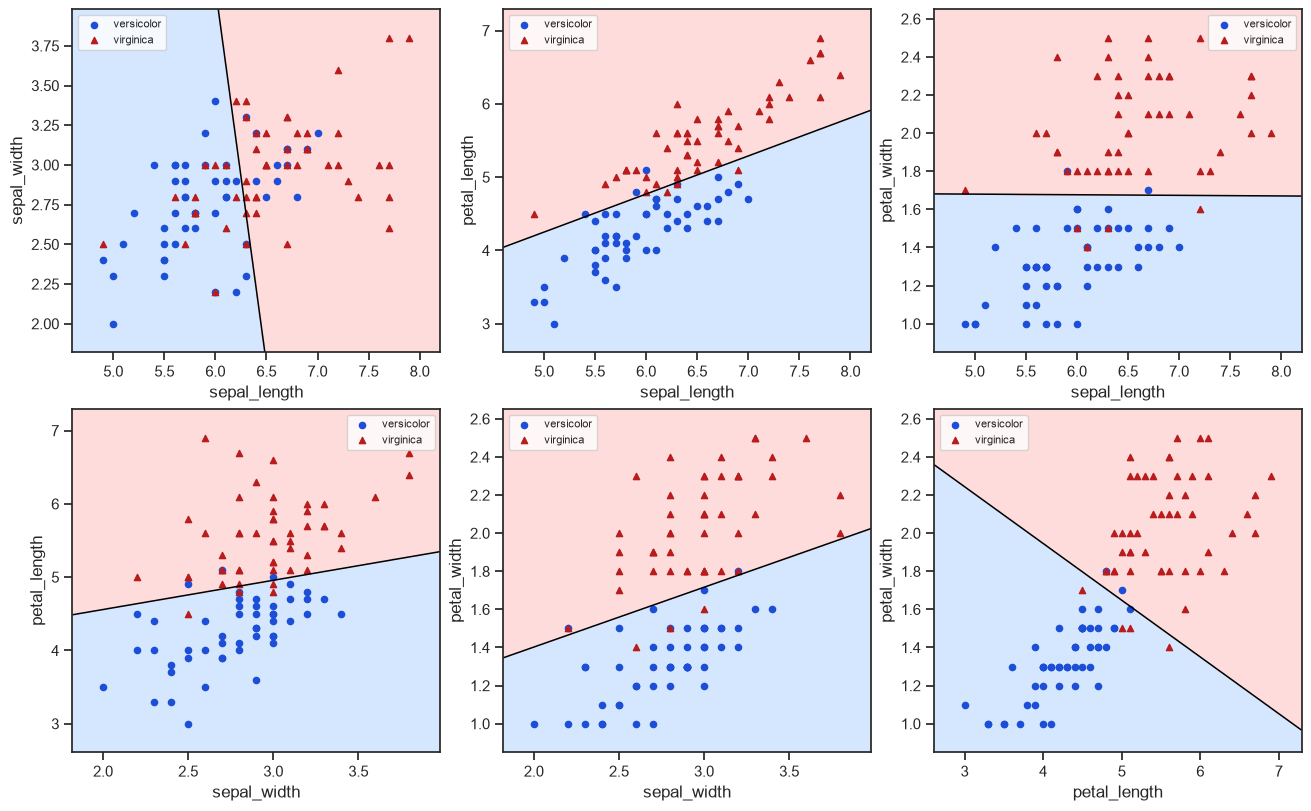

In [4]:
binary = df.loc[df["class"].isin(["versicolor", "virginica"])].copy()
labels = binary["class"].eq("virginica").astype(int)
pairs = list(itertools.combinations(features, 2))

def draw_boundary(ax, model, axes):
    points = binary[list(axes)].to_numpy()
    span = np.ptp(points, axis=0) * 0.10
    x, y = [np.linspace(lo, hi, 140) for lo, hi in
            zip(points.min(axis=0) - span, points.max(axis=0) + span)]
    xx, yy = np.meshgrid(x, y)
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    if hasattr(model, "decision_function"):
        values = model.decision_function(grid)
    else:
        values = model.predict_proba(grid)[:, 1] - 0.5
    scores = values.reshape(xx.shape)
    ax.contourf(xx, yy, scores >= 0, levels=[-0.5, 0.5, 1.5],
                colors=["#bfdbfe", "#fecaca"], alpha=0.65)
    ax.contour(xx, yy, scores, levels=[0], colors="black", linewidths=1.1)
    for label, name, marker, color in [(0, "versicolor", "o", "#1d4ed8"),
                                       (1, "virginica", "^", "#b91c1c")]:
        ax.scatter(*points[labels == label].T, label=name, marker=marker, c=color, s=20)
    ax.set(xlabel=axes[0], ylabel=axes[1])
    ax.legend(fontsize=8)

fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout="constrained")
for ax, pair in zip(axes.flat, pairs):
    model = LinearDiscriminantAnalysis().fit(binary[list(pair)].to_numpy(), labels)
    draw_boundary(ax, model, pair)
plt.show()

## Граница LDA и линейная регрессия

Линейная регрессия оценивает среднюю ширину лепестка при заданной длине.
Граница LDA разделяет виды по двум измерениям.

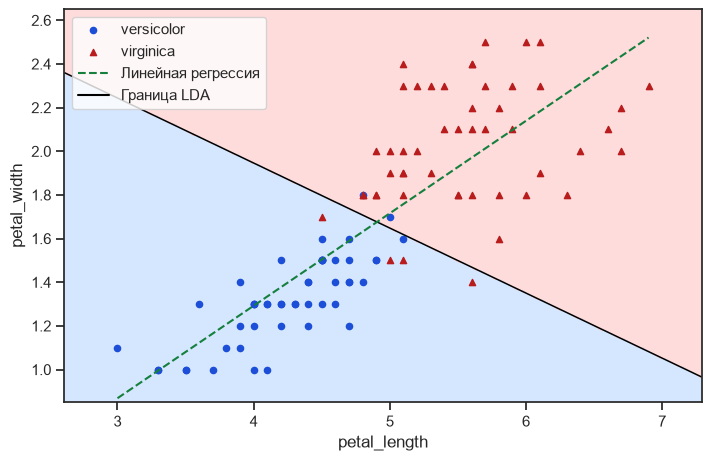

In [5]:
selected = ["petal_length", "petal_width"]
points = binary[selected].to_numpy()
lda = LinearDiscriminantAnalysis().fit(points, labels)
regression = LinearRegression().fit(points[:, :1], points[:, 1])

fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
draw_boundary(ax, lda, selected)
x = np.linspace(points[:, 0].min(), points[:, 0].max(), 150)
ax.plot(x, regression.predict(x[:, None]), "--", c="#15803d", label="Линейная регрессия")
ax.plot([], [], c="black", label="Граница LDA")
ax.legend()
plt.show()

## Сравнение четырёх моделей

Один стратифицированный train/test для всех моделей. Матрицы и ROC строим на тесте.
Для SVM используем RBF-ядро. Масштабирование SVM и логистической регрессии обучаем
только на тренировочных данных.

,Прогноз: versicolor,Прогноз: virginica
Истина: versicolor,14,1
Истина: virginica,3,12


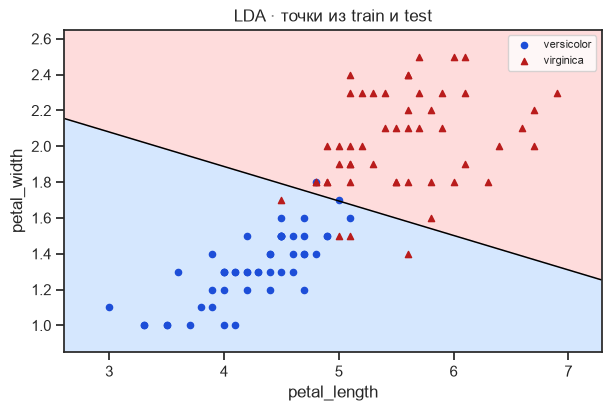

,Прогноз: versicolor,Прогноз: virginica
Истина: versicolor,14,1
Истина: virginica,2,13


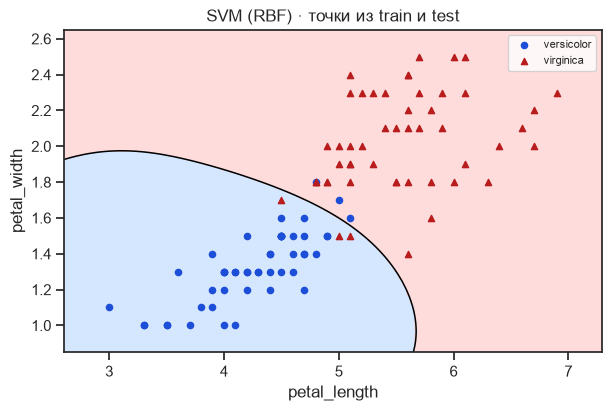

,Прогноз: versicolor,Прогноз: virginica
Истина: versicolor,14,1
Истина: virginica,2,13


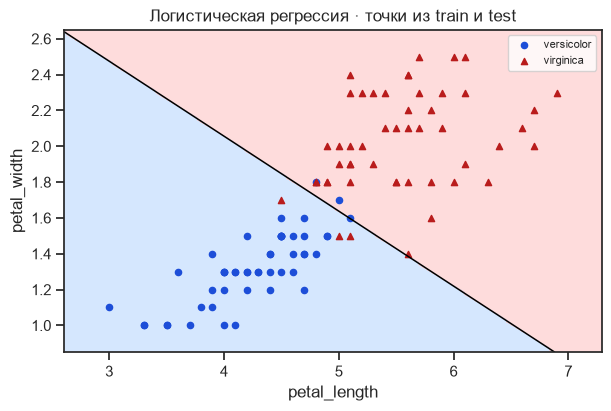

,Прогноз: versicolor,Прогноз: virginica
Истина: versicolor,14,1
Истина: virginica,2,13


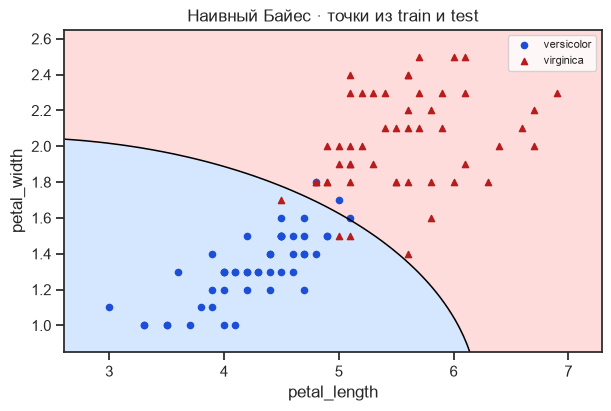

,sensitivity,specificity,precision,recall,AUROC
модель,,,,,
LDA,0.800,0.933,0.923,0.800,0.982
SVM (RBF),0.867,0.933,0.929,0.867,0.987
Логистическая регрессия,0.867,0.933,0.929,0.867,0.987
Наивный Байес,0.867,0.933,0.929,0.867,0.987


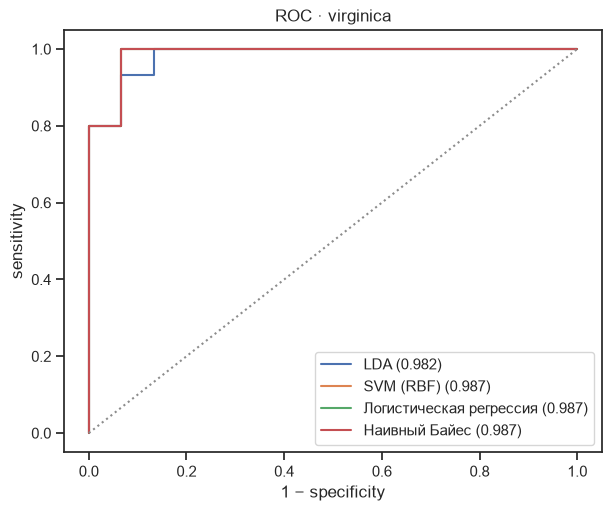

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    points, labels, test_size=0.30, stratify=labels, random_state=SEED,
)
models = {
    "LDA": LinearDiscriminantAnalysis(),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "Логистическая регрессия": make_pipeline(StandardScaler(), LogisticRegression()),
    "Наивный Байес": GaussianNB(),
}

fig, roc_ax = plt.subplots(figsize=(6, 5), layout="constrained")
plt.close(fig)
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    boundary_fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
    draw_boundary(ax, model, selected)
    ax.set_title(name + " · точки из train и test")
    matrix = confusion_matrix(y_test, model.predict(X_test), labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()
    display(pd.DataFrame(
        matrix, index=["Истина: versicolor", "Истина: virginica"],
        columns=["Прогноз: versicolor", "Прогноз: virginica"],
    ).style.set_caption(name))
    scores = (model.decision_function(X_test) if hasattr(model, "decision_function")
              else model.predict_proba(X_test)[:, 1])
    fpr, tpr, _ = roc_curve(y_test, scores)
    roc_auc = auc(fpr, tpr)
    results.append({
        "модель": name, "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "recall": tp / (tp + fn), "AUROC": roc_auc,
    })
    roc_ax.plot(fpr, tpr, label=f"{name} ({roc_auc:.3f})")
    plt.show()
display(pd.DataFrame(results).set_index("модель").round(3))
roc_ax.plot([0, 1], [0, 1], ":", color="0.55")
roc_ax.set(xlabel="1 − specificity", ylabel="sensitivity", title="ROC · virginica")
roc_ax.legend()
display(fig)
plt.close(fig)

Sensitivity и recall совпадают по определению. При 15 положительных объектах теста
одна ошибка меняет обе метрики примерно на 6,7 процентного пункта.
На этом разбиении AUROC составляет 0,982–0,987. У SVM, логистической регрессии
и наивного Байеса совпадают и AUROC, и матрицы ошибок.